# Deep Network Development, 2026 Autumn - Week 6 Practice - **Notebook for video recording**

## Loading data and converting it into a NumPy array

**Database:** Titanic Dataset - https://www.kaggle.com/datasets/yasserh/titanic-dataset (select all columns to browse the entire dataset at the website: "12 of 12 columns").

In the dataset, each row is a passenger of the Titanic ship. Various attributes of the passengers are available as variables of the dataset, including a binary classification label which tells us whether the passenger survived the sinking of the ship or not. These variables are the individual columns of the dataset.

In [ ]:
import numpy as np

titanic_csv_url = 'https://nipg12.inf.elte.hu/~vavsaai@nipg.lab/dndmsc_public_files/titanic.csv'

### Dataset CSV file loading - Option 1: Minimalist approach, loading as a string and processing it manually

Opening the file with the `urllib` module and loading its contents as a single, long UTF-8 string.

In [ ]:
# Option#1: read file with urllib

import urllib

with urllib.request.urlopen(titanic_csv_url) as ftpstream:
    dataset_content = ftpstream.read().decode('utf-8')
    print(len(dataset_content))
    print()
    print(dataset_content[:500])


INPUT_VAR_NAMES = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
input_var_names_objarr = np.array(INPUT_VAR_NAMES, dtype=object)


61194

PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,0,3,"Braund, Mr. Owen Harris",male,22,1,0,A/5 21171,7.25,,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26,0,0,STON/O2. 3101282,7.925,,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35,1,0,113803,53.1,C123,S
5,0,3,"Allen, Mr. William Henry",male,35,0,0,373450,8.05,,S
6,0,3,"Moran, Mr. James",male,,0,0,330


The string that contains the entire dataset has `\n` (newline) characters separating the rows of the dataset. Additionally, a comma character separates the different values in each line. Consequently, we could use the built-in `str.split()` function to split the long string at the newline characters into a list of strings where each string contains a row of the dataset. These could be further split into a list of strings for the individual values.

The problem with this approach now is that the dataset contains quoted string values in which commas can be found that conflict with the real separator characters of the dataset. As we will not need the content of the quoted strings (the names of the passengers), we will just remove these strings using the built-in `re` module. The main role of the `re` module is to perform various string operations which can be defined by the user with the RegExp (Regular Expression) syntax. If we needed to keep the names intact, we could use the `re.split()` method instead of the `str.split()` where splitting behaviour can be customized too.

(**Note:** RegExp is not going to be part of tests or exams.)

In [ ]:
# replace a single comma from the Name field to not interfere with the commas indicating dataset separators.

import re    # built-in regexp module
dataset_content = re.sub('"([^",]+),([^"]+)"', '"\g<1>\g<2>"', dataset_content)
print(len(dataset_content))
print()
print(dataset_content[:500])


60303

PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,0,3,"Braund Mr. Owen Harris",male,22,1,0,A/5 21171,7.25,,S
2,1,1,"Cumings Mrs. John Bradley (Florence Briggs Thayer)",female,38,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen Miss. Laina",female,26,0,0,STON/O2. 3101282,7.925,,S
4,1,1,"Futrelle Mrs. Jacques Heath (Lily May Peel)",female,35,1,0,113803,53.1,C123,S
5,0,3,"Allen Mr. William Henry",male,35,0,0,373450,8.05,,S
6,0,3,"Moran Mr. James",male,,0,0,330877,8.


<>:4: SyntaxWarning: invalid escape sequence '\g'
<>:4: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_2613/860260791.py:4: SyntaxWarning: invalid escape sequence '\g'
  dataset_content = re.sub('"([^",]+),([^"]+)"', '"\g<1>\g<2>"', dataset_content)


Following this, we can now split the long dataset string into a nested list of strings.

In [ ]:
lines = dataset_content.split('\n')
lines_segmented = [line.split(',') for line in lines]   # list (lines) of lists (words in each line)
attr_names = lines_segmented[0]
data = lines_segmented[1:-1]
print(attr_names)
print(data[:3])


['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked\r']
[['1', '0', '3', '"Braund Mr. Owen Harris"', 'male', '22', '1', '0', 'A/5 21171', '7.25', '', 'S\r'], ['2', '1', '1', '"Cumings Mrs. John Bradley (Florence Briggs Thayer)"', 'female', '38', '1', '0', 'PC 17599', '71.2833', 'C85', 'C\r'], ['3', '1', '3', '"Heikkinen Miss. Laina"', 'female', '26', '0', '0', 'STON/O2. 3101282', '7.925', '', 'S\r']]


We will now **convert the strings in the nested list to numbers** as our neural networks operate on numeric values. In the original dataset, there are variables with various value types:
- Those variables where the possible set of values is finite and the values are not naturally ordered will be handled as **categorical variables**. Such are "Sex" and "Embarked". The different categories are originally indicated by strings (e.g., "female"). For these, we create lookup dictionaries to help the conversion of string tags to integer category indices.
- Those variables where the values have a natural ordering will be regarded as **continuous variables**. In our case, these already have all numeric values, but encoded with characters. These can be converted directly into floating point numeric types using the `float()` built-in function. We will also handle integer-valued variables (e.g., "Pclass" - the ticket class of the passenger) as continuous variables and convert their values to floating point too.

**Certain variables will be dropped** as they do not contain useful information for us now. Such variables are "PassengerID", "Name" and "Cabin". We deem the "PassengerID" variable not useful for the estimation of the survival of the passenger as this is an arbitrarily created ID. The "Name" and "Cabin" variables may contain useful information -- for example, the nationality of the passenger may be inferred from their name or the cabin location may be extracted from the cabin IDs, and these might be correlated with the survival of the passengers. However, these dependencies can not directly be extracted without relying on additional information or data, so, for the sake of simplicity we will drop these variables too.

Some of our variables may have **missing values** for certain passengers. These are indicated by empty strings between the comma spearators. While for some machine learning models missing values do not cause problems, neural networks are not one of those. We will eventually need to handle missing values in some ways: either replace them, or completely remove affected rows/columns. We will not yet handle these, but we will indicate their presence in a numeric form too.

The floating point type has a few constant values reserved to represent special values, like infinity, negative infinity and NaN (not-a-number). In both base Python, NumPy, and PyTorch, these special values are available in floating point types. Integer and boolean data types do not have such standard constants to indicate erroneous numeric values.

Now **we will indicate missing values by using the NaN constant** instead of real numeric values.

In [ ]:

# INPUT_VAR_NAMES = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
sex_dict = {'female': 0, 'male': 1}
embarked_dict = {'C': 0, 'Q': 1, 'S': 2}

dataset = []
for rec in data:
    dataset_row = []
    for item_idx, item in enumerate(rec):
        item = item.strip()    # remove whitespace \r, \n from the two ends of the string
        if item_idx in {1, 2, 5, 6, 7, 9}:
            val = float('nan') if item == '' else float(item)
        elif item_idx == 4:
            val = sex_dict[item]
        elif item_idx == 11:
            val = float('nan') if item == '' else embarked_dict[item]
        else:
            continue
        dataset_row.append(val)
    dataset.append(dataset_row)

print(dataset[:30])

[[0.0, 3.0, 1, 22.0, 1.0, 0.0, 7.25, 2], [1.0, 1.0, 0, 38.0, 1.0, 0.0, 71.2833, 0], [1.0, 3.0, 0, 26.0, 0.0, 0.0, 7.925, 2], [1.0, 1.0, 0, 35.0, 1.0, 0.0, 53.1, 2], [0.0, 3.0, 1, 35.0, 0.0, 0.0, 8.05, 2], [0.0, 3.0, 1, nan, 0.0, 0.0, 8.4583, 1], [0.0, 1.0, 1, 54.0, 0.0, 0.0, 51.8625, 2], [0.0, 3.0, 1, 2.0, 3.0, 1.0, 21.075, 2], [1.0, 3.0, 0, 27.0, 0.0, 2.0, 11.1333, 2], [1.0, 2.0, 0, 14.0, 1.0, 0.0, 30.0708, 0], [1.0, 3.0, 0, 4.0, 1.0, 1.0, 16.7, 2], [1.0, 1.0, 0, 58.0, 0.0, 0.0, 26.55, 2], [0.0, 3.0, 1, 20.0, 0.0, 0.0, 8.05, 2], [0.0, 3.0, 1, 39.0, 1.0, 5.0, 31.275, 2], [0.0, 3.0, 0, 14.0, 0.0, 0.0, 7.8542, 2], [1.0, 2.0, 0, 55.0, 0.0, 0.0, 16.0, 2], [0.0, 3.0, 1, 2.0, 4.0, 1.0, 29.125, 1], [1.0, 2.0, 1, nan, 0.0, 0.0, 13.0, 2], [0.0, 3.0, 0, 31.0, 1.0, 0.0, 18.0, 2], [1.0, 3.0, 0, nan, 0.0, 0.0, 7.225, 0], [0.0, 2.0, 1, 35.0, 0.0, 0.0, 26.0, 2], [1.0, 2.0, 1, 34.0, 0.0, 0.0, 13.0, 2], [1.0, 3.0, 0, 15.0, 0.0, 0.0, 8.0292, 1], [1.0, 1.0, 1, 28.0, 0.0, 0.0, 35.5, 2], [0.0, 3.0, 0, 8.0,

The dataset, at this point, is stored in the form of a nested list of numbers. As we prefer to process this dataset efficiently, we will **convert this structure into a 2D NumPy array**. The shape of the array is `(n_passengers, n_variables)`, where we have a total of 891 passengers. Data about a single passenger is stored in a single row. The datatype will be `float32`, the 4-byte floating point format (also sometimes referred to as _single precision_ datatype) as this is the standard format of storing arbitrary real values. GPUs are, for example optimized for computing with the `float32` datatype, but are generally really inefficient when handling `float64` datatypes.

The first column of the array contains the **survival information of passengers**. This is a categorical variable with two possible values (0 for passengers who died and 1 for those who survived). In this notebook we will only use this variable as the target variable, the expected output of our model, in other words, the label variable. Accordingly, **we will separate this single column into an 1D array named `labels`** with a shape of `(n_passengers,)` and for now, it will have an integer data type.

**The remaining part of the 2D array will be named `inputs` as the input variables of the neural network will be derived from these**. We will use the general `np.float32` data type for these values.

In [ ]:

dataset_arr = np.array(dataset, dtype=np.float32)
print(dataset_arr[:5])
print(dataset_arr.shape)

inputs = dataset_arr[:,1:]
print(f"inputs array shape: {inputs.shape}, dtype: {inputs.dtype}")
print(inputs[:5, :])
labels = dataset_arr[:,0].astype(np.int32)
print(f"labels array shape: {labels.shape}, dtype: {labels.dtype}")
print(labels[:5])

[[ 0.      3.      1.     22.      1.      0.      7.25    2.    ]
 [ 1.      1.      0.     38.      1.      0.     71.2833  0.    ]
 [ 1.      3.      0.     26.      0.      0.      7.925   2.    ]
 [ 1.      1.      0.     35.      1.      0.     53.1     2.    ]
 [ 0.      3.      1.     35.      0.      0.      8.05    2.    ]]
(891, 8)
inputs array shape: (891, 7), dtype: float32
[[ 3.      1.     22.      1.      0.      7.25    2.    ]
 [ 1.      0.     38.      1.      0.     71.2833  0.    ]
 [ 3.      0.     26.      0.      0.      7.925   2.    ]
 [ 1.      0.     35.      1.      0.     53.1     2.    ]
 [ 3.      1.     35.      0.      0.      8.05    2.    ]]
labels array shape: (891,), dtype: int32
[0 1 1 1 0]


We will later check out additional ways to load tabular datasets from text files.

## Data exploration

### Exploration of missing values

**Task:** Get the total number of missing values among the input variables.

For the testing of equality against `NaN` values, the `my_array == np.nan` is not a correct solution. NaN values have some special properties to increase the chance of them propagating errors throughout the subsequently used operations so their presence is revealed to the programmer with a higher chance. On of the special properties of `np.nan` is that `np.nan == np.nan` is False by definition. Therefore, `my_array == np.nan` will always be an all-False mask.

Instead, we have to use the `np.isnan()` function.

In [ ]:

#missing_inputs_mask = inputs == np.nan   # DOES NOT WORK! np.nan is not equal with any value by definiton. np.nan == np.nan is False.

missing_inputs_mask = np.isnan(inputs)    # The np.isnan() element-wise operation will return True for NaN values and False for any other values in an array.
                                          # Same shape as `inputs`: (n_passengers, n_input_vars)

print("How many NaNs are in the dataset?", np.count_nonzero(missing_inputs_mask))


How many NaNs are in the dataset? 179


**Task:** Find out if there are missing labels or not.

In [ ]:

print("Are there missing labels?", np.any(np.isnan(labels)) )


Are there missing labels? False


**Task:** Find out how many passengers (rows) have missing values in the input variables array.

In [ ]:

print("How many passengers (rows) have missing values in inputs?", np.count_nonzero(np.any(missing_inputs_mask, axis=1)))


How many passengers (rows) have missing values in inputs? 179


**Task:** Find out which variables (columns) have missing values and how many for each.

In [ ]:

print("Which variables (columns) indices have NaNs in inputs?", np.where(np.any(missing_inputs_mask, axis=0))[0])
print("Which variables (columns) by name have NaNs in inputs?", input_var_names_objarr[np.any(missing_inputs_mask, axis=0)])

print("\nHow many NaNs are in each column of the input?", np.count_nonzero(missing_inputs_mask, axis=0))


Which variables (columns) indices have NaNs in inputs? [2 6]
Which variables (columns) by name have NaNs in inputs? ['Age' 'Embarked']

How many NaNs are in each column of the input? [  0   0 177   0   0   0   2]


### A few basic statistics

**Task:** Find the minimum, maximum and mean (average) of each variable.

In [ ]:

var_mins = np.amin(inputs, axis=0)
var_maxes = np.amax(inputs, axis=0)
var_means = np.mean(inputs, axis=0)

print("Minimum of each variable: ", dict(zip(INPUT_VAR_NAMES, var_mins)))      # inefficient, only used for printing: create a dictionary from pairs coming from two iterables
print("Maximum of each variable: ", dict(zip(INPUT_VAR_NAMES, var_maxes)))
print("Mean of each variable: ", dict(zip(INPUT_VAR_NAMES, var_means)))

print("\nPrettier printing:\n")     # NumPy scalars after version 2.0 have a very verbose string representation e.g., "np.float32(1.0)" to avoid mixing it up with basic Python types, so printing these does not look nice

print("Minimum of each variable: ", var_mins)                                  # printing ndarrays does not have this problem
print("Minimum of first variable: ", float(var_mins[0]))                       # can convert numpy scalar to float to have prettier printing
print("Minimum of each variable: ", dict(zip(INPUT_VAR_NAMES, map(float, var_mins))))    # applying the float() built-in function on each element of the array
print("Maximum of each variable: ", dict(zip(INPUT_VAR_NAMES, map(float, var_maxes))))
print("Mean of each variable: ", dict(zip(INPUT_VAR_NAMES, map(float, var_means))))



Minimum of each variable:  {'Pclass': np.float32(1.0), 'Sex': np.float32(0.0), 'Age': np.float32(nan), 'SibSp': np.float32(0.0), 'Parch': np.float32(0.0), 'Fare': np.float32(0.0), 'Embarked': np.float32(nan)}
Maximum of each variable:  {'Pclass': np.float32(3.0), 'Sex': np.float32(1.0), 'Age': np.float32(nan), 'SibSp': np.float32(8.0), 'Parch': np.float32(6.0), 'Fare': np.float32(512.3292), 'Embarked': np.float32(nan)}
Mean of each variable:  {'Pclass': np.float32(2.308642), 'Sex': np.float32(0.647587), 'Age': np.float32(nan), 'SibSp': np.float32(0.52300787), 'Parch': np.float32(0.3815937), 'Fare': np.float32(32.204247), 'Embarked': np.float32(nan)}

Prettier printing:

Minimum of each variable:  [ 1.  0. nan  0.  0.  0. nan]
Minimum of first variable:  1.0
Minimum of each variable:  {'Pclass': 1.0, 'Sex': 0.0, 'Age': nan, 'SibSp': 0.0, 'Parch': 0.0, 'Fare': 0.0, 'Embarked': nan}
Maximum of each variable:  {'Pclass': 3.0, 'Sex': 1.0, 'Age': nan, 'SibSp': 8.0, 'Parch': 6.0, 'Fare': 512.

A problem -- slices with NaN values will have a NaN minimum, maximum and mean.

`np.nanmin`, `np.nanmax`, `np.nanmean`, etc. collapse functions will ignore NaN values.

In [ ]:

var_mins = np.nanmin(inputs, axis=0)
var_maxes = np.nanmax(inputs, axis=0)
var_means = np.nanmean(inputs, axis=0)

print("Minimum of each variable: ", dict(zip(INPUT_VAR_NAMES, map(float, var_mins))))
print("Maximum of each variable: ", dict(zip(INPUT_VAR_NAMES, map(float, var_maxes))))
print("Mean of each variable: ", dict(zip(INPUT_VAR_NAMES, map(float, var_means))))


Minimum of each variable:  {'Pclass': 1.0, 'Sex': 0.0, 'Age': 0.41999998688697815, 'SibSp': 0.0, 'Parch': 0.0, 'Fare': 0.0, 'Embarked': 0.0}
Maximum of each variable:  {'Pclass': 3.0, 'Sex': 1.0, 'Age': 80.0, 'SibSp': 8.0, 'Parch': 6.0, 'Fare': 512.3292236328125, 'Embarked': 2.0}
Mean of each variable:  {'Pclass': 2.3086419105529785, 'Sex': 0.6475870013237, 'Age': 29.69911766052246, 'SibSp': 0.523007869720459, 'Parch': 0.3815937042236328, 'Fare': 32.204246520996094, 'Embarked': 1.535433053970337}


**Task:** Find the age of the five oldest passengers.

In [ ]:

AGE_COL_IDX = INPUT_VAR_NAMES.index('Age')

sorted_ages = np.sort(inputs[:, AGE_COL_IDX])

print("Five highest age values: ", sorted_ages[-5:])


Five highest age values:  [nan nan nan nan nan]


This would work well if there were no NaN values in the 'Age' column, but there are. Unfortunately, there is no "nansort" operation. Since NumPy 1.4, `np.sort()` consistently sorts NaN values at the back. This would help in the case we wanted to find the youngest passengers, but now we need the oldest ones. As NaNs are at the very end, the oldest are right before them in the result at an unknown position.

Since we only sort a single column (with no axis parameter), we can solve this issue easily:
- By masking out NaN values first and sorting the filtered array.
- Or, by setting NaN values to a very small number (negative infinity) so they will be at the beginning instead of the end.

In [ ]:

# Approach #1: masking out NaN values first and sorting the filtered array

age_values = inputs[:, AGE_COL_IDX]    # (n_passengers,)
filtered_age_values = age_values[~np.isnan(age_values)]

sorted_ages = np.sort(filtered_age_values)

print("Five highest age values: ", sorted_ages[-5:])

# Approach #2: setting NaN values to a very small number (negative infinity) so they will be at the beginning instead of the end

age_values = inputs[:, AGE_COL_IDX].copy()    # (n_passengers,), copying to not modify the original inputs array, as the extracted column is a view of it
age_values[np.isnan(age_values)] = -np.inf

sorted_ages = np.sort(age_values)

print("\nFive highest age values: ", sorted_ages[-5:])



Five highest age values:  [70.5 71.  71.  74.  80. ]

Five highest age values:  [70.5 71.  71.  74.  80. ]


**Task:** Find the median ticket price.

Fortunately, the ticket price column does not contain NaN values. Median is, by definition the middle value in the sorted sequence of values, or if the number of values is even, then the mean of the two middle values.

First, we can take this approach, then a more direct approach using `np.median()`. (By the way, `np.nanmedian()` exists too.)

In [ ]:

TICKET_PRICE_COL_IDX = INPUT_VAR_NAMES.index('Fare')

# Approach #1: Median is, by definition the middle value in the sorted sequence of values, or if the number of values is even, then the mean of the two middle values
n_passengers = inputs.shape[0]

sorted_ticket_prices = np.sort(inputs[:, TICKET_PRICE_COL_IDX])

if n_passengers % 2 == 0:
    assert n_passengers >= 2
    middle_first_idx = (n_passengers // 2)-1
    median_ticket_price = np.mean(sorted_ticket_prices[ middle_first_idx : middle_first_idx+2 ])
else:
    middle_idx = n_passengers // 2
    median_ticket_price = sorted_ticket_prices[middle_idx]

print("The median ticket price", median_ticket_price)

# Approach #2: using np.median()

print("\nThe median ticket price", np.median(inputs[:, TICKET_PRICE_COL_IDX]))


The median ticket price 14.4542

The median ticket price 14.4542


**Task:** Find the top-5 lowest values for each variable.

`np.sort()` is a vectorized operation, so we can use its `axis` parameter to perform sorting of multiple slices of an array independently, at once.

In [ ]:

lowest5_values_for_each_var = np.sort(inputs, axis=0)[:5, :]    # (5, n_input_vars)

print("The 5 lowest values for each input variable:\n", lowest5_values_for_each_var)

# Prettier printing
print("\nPrettier printing with a dictionary:\n")

print("The 5 lowest values for each input variable:\n", dict(zip(INPUT_VAR_NAMES, lowest5_values_for_each_var.T)))



The 5 lowest values for each input variable:
 [[1.   0.   0.42 0.   0.   0.   0.  ]
 [1.   0.   0.67 0.   0.   0.   0.  ]
 [1.   0.   0.75 0.   0.   0.   0.  ]
 [1.   0.   0.75 0.   0.   0.   0.  ]
 [1.   0.   0.83 0.   0.   0.   0.  ]]

Prettier printing with a dictionary:

The 5 lowest values for each input variable:
 {'Pclass': array([1., 1., 1., 1., 1.], dtype=float32), 'Sex': array([0., 0., 0., 0., 0.], dtype=float32), 'Age': array([0.42, 0.67, 0.75, 0.75, 0.83], dtype=float32), 'SibSp': array([0., 0., 0., 0., 0.], dtype=float32), 'Parch': array([0., 0., 0., 0., 0.], dtype=float32), 'Fare': array([0., 0., 0., 0., 0.], dtype=float32), 'Embarked': array([0., 0., 0., 0., 0.], dtype=float32)}


**Task:** Find the top-5 highest values for each variable.

Now, we may again have problems with NaN values, as they are sorted to the end of the slices and we need to extract elements positioned at the end of the slices. An added difficulty is that now we want to sort in a vectorized way, along multiple slices at once, and the are a different number of NaN values in the various slices (columns). A number of options are available to handle the situation:
- From NumPy 2.5, `np.sort()` will arrange NaN values at the end of the ordering. To be able to select the highest real values, `descending=True` needs to be specified in the function, so the order is reversed, but the NaN values will still stay at the end of the order.
- From NumPy 2.6, `np.top_k()` is available that can handle NaNs correctly as well, for both the lowest and highest values.
- We could go column-by-column and perform sorting on the individual columns, each filtered for NaN before sorting. This is less elegant than the vectorized way and it involves a Python loop, so in case we have many columns, this is not very efficient.
- Replace NaN values with negative infinity values in the entire array and then perform sorting. We need to make sure that negative infinity does not interfere with our real values. (**We will choose this one.**)

In [ ]:

inputs_copy = inputs.copy()    # copying to not modify the original inputs array, as the extracted column is a view of it
inputs_copy[np.isnan(inputs_copy)] = -np.inf


highestt5_values_for_each_var = np.sort(inputs_copy, axis=0)[-5:, :]    # (5, n_input_vars)

print("The 5 highest values for each input variable:\n", highestt5_values_for_each_var)

# Prettier printing
print("\nPrettier printing with a dictionary:\n")

print("The 5 highest values for each input variable:\n", dict(zip(INPUT_VAR_NAMES, highestt5_values_for_each_var.T)))



The 5 highest values for each input variable:
 [[  3.       1.      70.5      8.       5.     263.       2.    ]
 [  3.       1.      71.       8.       5.     263.       2.    ]
 [  3.       1.      71.       8.       5.     512.3292   2.    ]
 [  3.       1.      74.       8.       5.     512.3292   2.    ]
 [  3.       1.      80.       8.       6.     512.3292   2.    ]]

Prettier printing with a dictionary:

The 5 highest values for each input variable:
 {'Pclass': array([3., 3., 3., 3., 3.], dtype=float32), 'Sex': array([1., 1., 1., 1., 1.], dtype=float32), 'Age': array([70.5, 71. , 71. , 74. , 80. ], dtype=float32), 'SibSp': array([8., 8., 8., 8., 8.], dtype=float32), 'Parch': array([5., 5., 5., 5., 6.], dtype=float32), 'Fare': array([263.    , 263.    , 512.3292, 512.3292, 512.3292], dtype=float32), 'Embarked': array([2., 2., 2., 2., 2.], dtype=float32)}


**Task:** Find the ticket price of the five oldest and five youngest passengers.

When we need to find specific values of another column corresponding to the order of values in another column, we should use `np.argsort()`. Instead of returning the sorted array, `np.argsort()` will return a permutation of integer indices which can be used to sort the array when used with integer sequence indexing.

Therefore, we can get the sorting index permutation (a sorter) of the age column and apply this permutation to re-order the ticket price column. Or, if we only need to extract a few elements, we can extract the appropriate indices from the sorter and index into the ticket price column with those.

In [ ]:

age_sorter = np.argsort(inputs[:, AGE_COL_IDX])  # (n_passengers,) int64

# The five youngest passenger

five_youngest_passenger_idx = age_sorter[:5]     # (5,) int64
print("The ticket prices for the 5 youngest passengers:", inputs[five_youngest_passenger_idx, TICKET_PRICE_COL_IDX])

# The five oldest passenger

five_oldest_passenger_idx = age_sorter[-5:]      # (5,) int64

print("\nThe ticket prices for the 5 oldest passengers:", inputs[five_oldest_passenger_idx, TICKET_PRICE_COL_IDX])   # INCORRECT RESULTS because of NaNs sorted to the end!
print("Age for the 5 oldest passengers:", inputs[five_oldest_passenger_idx, AGE_COL_IDX])                          # INCORRECT RESULTS because of NaNs sorted to the end!



The ticket prices for the 5 youngest passengers: [ 8.5167 14.5    19.2583 19.2583 18.75  ]

The ticket prices for the 5 oldest passengers: [15.2458 26.55   69.55    7.25    7.225 ]
Age for the 5 oldest passengers: [nan nan nan nan nan]


Incorrect results for the oldest passengers, due to NaNs.

When filtering NaNs and dropping elements from an array, we need to pay attention to the shifting of indices due to the dropped elements.

In [ ]:

# Approach #1 (relying on np.argsort() placing NaNs at the end)

n_nans = np.count_nonzero(np.isnan(inputs[:, AGE_COL_IDX]))

age_sorter = np.argsort(inputs[:, AGE_COL_IDX])       # (n_passengers,) int64; same sorter as before

five_oldest_passenger_idx = age_sorter[-n_nans-5 : -n_nans]      # (5,) int64

print("\nThe ticket prices for the 5 oldest passengers:", inputs[five_oldest_passenger_idx, TICKET_PRICE_COL_IDX])
print("Age for the 5 oldest passengers:", inputs[five_oldest_passenger_idx, AGE_COL_IDX])



# Approach #2 (more general, not relying on NaNs being at the end when sorting)

age_sorter = np.argsort(inputs[:, AGE_COL_IDX])       # (n_passengers,) int64; same sorter as before

nan_age_mask = np.isnan(inputs[:, AGE_COL_IDX])       # (n_passengers,) bool_, masking original passenger order
nan_age_mask_reordered = nan_age_mask[age_sorter]     # (n_passengers,) bool_, masking in the age sorted order

age_sorter_skip_nans = age_sorter[~nan_age_mask_reordered]     # masking sorter indices with the re-ordered mask

five_oldest_passenger_idx = age_sorter_skip_nans[-5:]      # (5,) int64
print("\nThe ticket prices for the 5 oldest passengers:", inputs[five_oldest_passenger_idx, TICKET_PRICE_COL_IDX])
print("Age for the 5 oldest passengers:", inputs[five_oldest_passenger_idx, AGE_COL_IDX])




The ticket prices for the 5 oldest passengers: [ 7.75   49.5042 34.6542  7.775  30.    ]
Age for the 5 oldest passengers: [70.5 71.  71.  74.  80. ]

The ticket prices for the 5 oldest passengers: [ 7.75   49.5042 34.6542  7.775  30.    ]
Age for the 5 oldest passengers: [70.5 71.  71.  74.  80. ]


Additional features related to sorting:
- `stable=True` in sorting operations: If a sorting is stable, the original order of such values that are equal to each other is preserved. Stable sorting is useful, when we want to sort an array using multiple slices. For example, if we wanted to reorder the rows of the dataset so that it is sorted by the age of the passengers and those passengers which have the same age are additionally sorted by their ticket prices, we could first have a sorter created (with `np.argsort()`) based on the ticket prices, use this sorter to reorder the rows of the dataset, then have a stable sorter created which sorts the age column without modifying the order of passengers with equal age. Finally, apply this second sorter to reorder the rows of the dataset again.
- `np.lexsort()`: Lexicographical sorting. Performs the functionality described above using multiple stable sorting operations.
- `np.searchsorted()`: Logarithmic-time searching of multiple values in a sorted array.

### Distribution of discrete / categorical variables

**Task:** Get the distribution of ticket classes. (In other words, the number of passengers falling into the different ticket classes.)

We need to find all the different values present in the ticket class column and tell the frequency of each value. For such a task we have two main efficient approaches:
- `np.unique()`: Returns an array of the unique values present in an array. The `np.unique()` function has several flag parameters which enable additional functionality. The one we will use here is:
    - `return_counts`: In another array, returns the frequencies of the elements in the unique array.
- `np.bincount()`: Returns an array of shape `(array_max+1,)` where the frequencies of integers from 0 to `array_max` are listed. Only works on integer arrays. It is more efficient to compute than `np.unique()` if the array maximum is not much larger than the number of unique values of the array. Inefficient if the array maximum is much larger than the number of unique elements: a huge, sparse array needs to be created in that case. A `minlength` parameter can be provided if we need a certain minimum length to the result array.

In [ ]:

TICKET_CLASS_COL_IDX = INPUT_VAR_NAMES.index('Pclass')

u_ticket_class_vals, count_ticket_class_vals = np.unique(inputs[:, TICKET_CLASS_COL_IDX], return_counts=True)     # Using np.unique(): less efficient, but can be used on any values

print("The unique ticket class values:", u_ticket_class_vals, "; and the corresponding frequencies", count_ticket_class_vals)

# An alternative

ticket_classes_i = inputs[:, TICKET_CLASS_COL_IDX].astype(np.int64)    # np.bincount() only works on integers

bincount_ticket_class_vals = np.bincount(ticket_classes_i)     # Using np.bincount(): more efficient, but returns value frequencies in an array shaped (max_arr_value,) which is not ideal if values are spread out

print("\nnp.bincount() result on ticket classes:", bincount_ticket_class_vals)


The unique ticket class values: [1. 2. 3.] ; and the corresponding frequencies [216 184 491]

np.bincount() result on ticket classes: [  0 216 184 491]


Additional flag parameters of the `np.unique()` function:
- `return_index`: Returns the index of the first occurrence of each element in the unique array.
- `return_inverse`: Returns a copy of the original array where the elements are replaced by the indices of the corresponding elements from the unique array. Indexing the unique array with this inverse array will thus reconstruct the original array. A use case: Often, it is better / more efficient to work with values from a $[0, nUniqueElements)$ range rather than with the original array values.

`np.unique()` can also be used with an axis parameter, but this does not correspond to a vectorized behaviour: instead, unique slices of the array will be extracted.

**Task:** Plot the distribution of the ticket class (discrete) variable as a bar plot.

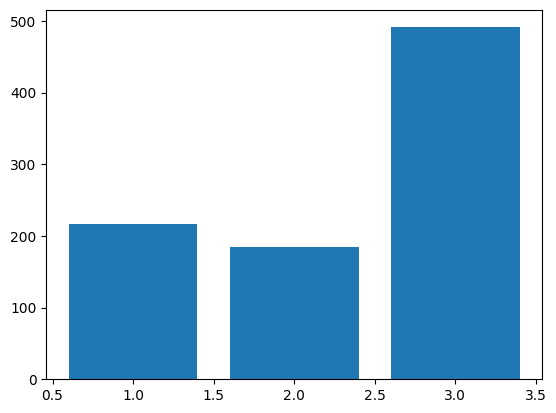

In [ ]:
# Only makes sense if the variable has just a few possible values

import matplotlib.pyplot as plt

plt.bar(u_ticket_class_vals, count_ticket_class_vals)
plt.show()


**Task:** Get the distribution of ticket classes separately for men and women.

In [ ]:

TICKET_CLASS_COL_IDX = INPUT_VAR_NAMES.index('Pclass')    # 1, 2 or 3
SEX_COL_IDX = INPUT_VAR_NAMES.index('Sex')                # female: 0, male: 1

females_mask = inputs[:, SEX_COL_IDX] == 0                # (n_passengers,) bool_

u_fem_ticket_class_vals, count_fem_ticket_class_vals = np.unique(inputs[females_mask, TICKET_CLASS_COL_IDX], return_counts=True)

u_male_ticket_class_vals, count_male_ticket_class_vals = np.unique(inputs[~females_mask, TICKET_CLASS_COL_IDX], return_counts=True)

print("The unique ticket class values for women only:", u_fem_ticket_class_vals, "; and the corresponding frequencies:", count_fem_ticket_class_vals)
print("The unique ticket class values for men only:", u_male_ticket_class_vals, "; and the corresponding frequencies:", count_male_ticket_class_vals)


The unique ticket class values for women only: [1. 2. 3.] ; and the corresponding frequencies: [ 94  76 144]
The unique ticket class values for men only: [1. 2. 3.] ; and the corresponding frequencies: [122 108 347]


**Task:** Plot the distribution of the ticket classes separately for men and women on two bar plots. Make sure the vertical axis (the number of passengers) is shared between the two plots.

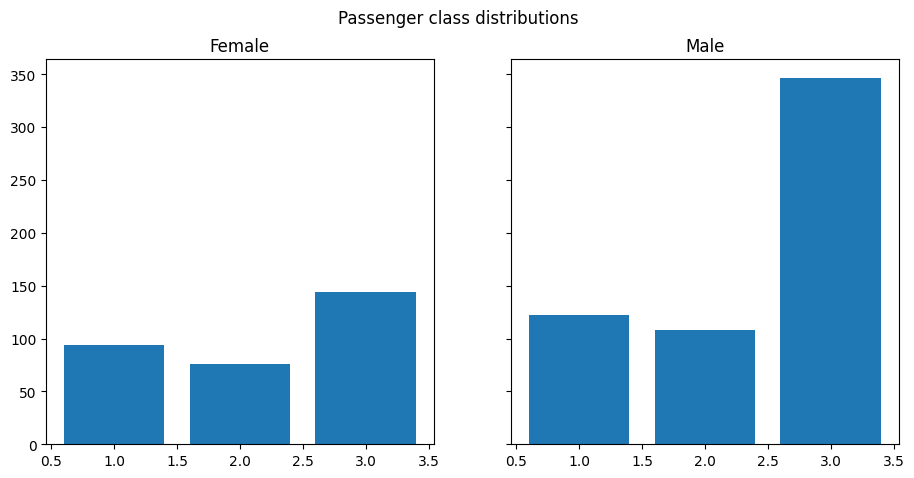

In [ ]:
# Multiple barcharts showing passenger class distribution of males and females separately

figure, axes = plt.subplots(nrows=1, ncols=2, sharey=True, figsize=(11,5))
axes[0].bar(u_fem_ticket_class_vals, count_fem_ticket_class_vals)
axes[0].set_title('Female')
axes[1].bar(u_male_ticket_class_vals, count_male_ticket_class_vals)
axes[1].set_title('Male')
figure.suptitle('Passenger class distributions')
plt.show()


_(**A quick detour for a more advanced example:** Assume for now that men only travel on 2nd and 3rd classes, while women in 1st and 2nd classes. Let's still create the frequency arrays for all three classes - in a general way.)_

In [ ]:
# Assumption for now just for this example:
u_fem_ticket_class_vals = np.array([1, 2])
count_fem_ticket_class_vals = np.array([150, 75])

u_male_ticket_class_vals = np.array([2, 3])
count_male_ticket_class_vals = np.array([80, 120])
#


u_shared_ticket_class_vals = np.union1d(u_fem_ticket_class_vals, u_male_ticket_class_vals)  # Could just use `u_ticket_class_vals`, but instead showing that set operations also exist in NumPy

female_u_indices = np.searchsorted(u_shared_ticket_class_vals, u_fem_ticket_class_vals)     # Finding index of ticket class values used by females within all ticket class values
                                                                                            # `u_shared_ticket_class_vals` is sorted, so no need to sort it to use it with log(n)-time np.searchsorted()
male_u_indices = np.searchsorted(u_shared_ticket_class_vals, u_male_ticket_class_vals)     # Finding index of ticket class values used by males within all ticket class values

count_shared_fem_ticket_class_vals = np.zeros_like(u_shared_ticket_class_vals)
count_shared_fem_ticket_class_vals[female_u_indices] = count_fem_ticket_class_vals

count_shared_male_ticket_class_vals = np.zeros_like(u_shared_ticket_class_vals)
count_shared_male_ticket_class_vals[male_u_indices] = count_male_ticket_class_vals

print("(NOT THE REAL VALUES) The unique ticket class values:", u_shared_ticket_class_vals, "; female frequencies:", count_shared_fem_ticket_class_vals, "; male frequencies:", count_shared_male_ticket_class_vals)


(NOT THE REAL VALUES) The unique ticket class values: [1 2 3] ; female frequencies: [150  75   0] ; male frequencies: [  0  80 120]


Set operations in NumPy: `np.union1d()`, `np.intersect1d()`, `np.setdiff1d()`, `np.isin()`, etc.
- Set operations on integer indices provide an alternative to element-wise logical operations on masks. For example, taking the element-wise conjunction (logical AND) of masks is equivalent to taking the intersection of integer index arrays. Converting masks to integer indices and performing set operations on them can be a more efficient alternative to mask operations when the masks are large and very sparse.

### Distribution of continuous variables

**Task:** Compute a histogram (approximate visualization of distribution) of the age of passengers.

There are a lot of possible values for age, so counting the frequency of individual values is not informative. Instead, we define intervals (bins) for the age variable and count the frequency of people falling in each age group. This is how a _histogram_ of the variable is computed.

In [ ]:

AGE_COL_IDX = INPUT_VAR_NAMES.index('Age')
SEX_COL_IDX = INPUT_VAR_NAMES.index('Sex')                # female: 0, male: 1

hist, bin_edges = np.histogram(inputs[~np.isnan(inputs[:, AGE_COL_IDX]), AGE_COL_IDX])

print("Histogram of age distribution of passengers:")
print("    bin edges:", bin_edges)
print("    bin counts:", hist)


Histogram of age distribution of passengers:
    bin edges: [ 0.42   8.378 16.336 24.294 32.252 40.21  48.168 56.126 64.084 72.042
 80.   ]
    bin counts: [ 54  46 177 169 118  70  45  24   9   2]


**Task:** Plot the age distribution (histogram) of four groups of people on a figure of 2-by-2 plots:
- Women who survived
- Women who died
- Men who survived
- Men who died

Make sure that the histograms use the same bin edges (age group boundaries).

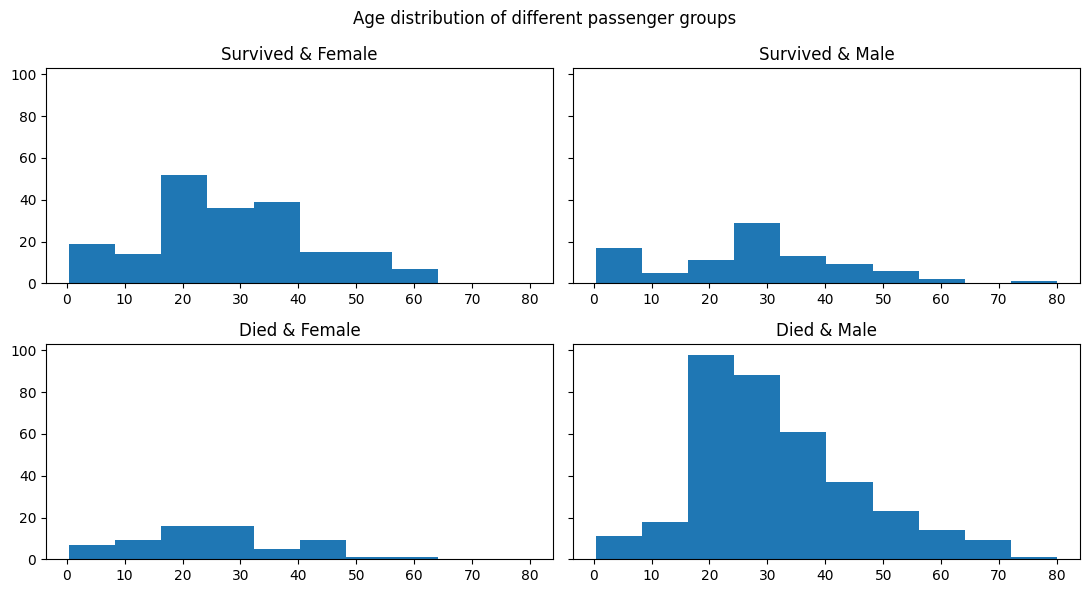

In [ ]:

females_mask = inputs[:, SEX_COL_IDX] == 0                # (n_passengers,) bool_
survived_mask = labels == 1                               # (n_passengers,) bool_

min_age, max_age = np.nanmin(inputs[:, AGE_COL_IDX]), np.nanmax(inputs[:, AGE_COL_IDX])   # ignoring NaNs where age is missing


age_values_grouped = np.array([[inputs[females_mask & survived_mask, AGE_COL_IDX], inputs[~females_mask & survived_mask, AGE_COL_IDX]],
                               [inputs[females_mask & ~survived_mask, AGE_COL_IDX], inputs[~females_mask & ~survived_mask, AGE_COL_IDX]]], dtype=object)      # place age values of the four groups as 1D arrays inside a (2, 2) shaped object array for convenience (not efficient)

N_BINS = 10
PLOT_TITLE_ROWS = ['Survived', 'Died']
PLOT_TITLE_COLS = ['Female', 'Male']

fig, axs = plt.subplots(nrows=2, ncols=2, sharey=True, tight_layout=True, figsize=(11,6))
fig.suptitle('Age distribution of different passenger groups')
for row_idx in range(2):
    for col_idx in range(2):
        axs[row_idx, col_idx].hist(age_values_grouped[row_idx, col_idx], bins=N_BINS, range=(min_age, max_age))    # The same age value range is specified for each histogram. As the number of bins is the same, the bin edges will be the same too.
                                                                                                                   # Alternative#1: Manually create bin edges with np.linspace()
                                                                                                                   # Alternative#2: Manually create bin edges with np.histogram_bin_edges()
                                                                                                                   #     We are using plt.hist() directly which is implemented as a combination of plt.bar() and np.histogram().
        axs[row_idx, col_idx].set_title(PLOT_TITLE_ROWS[row_idx] + ' & ' + PLOT_TITLE_COLS[col_idx])
plt.show()




### Scatter plots

Scatter plots can be used to display 2D points.

**Task:** Create a scatter plot showing the age and ticket price values of passengers. The points should be colored based on whether the passenger died or survived. Make sure the ticket price axis is using a logarithmic scale, as there are a few very expensive tickets.

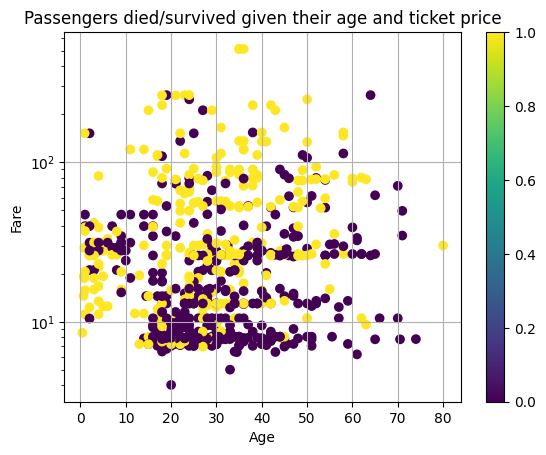

In [ ]:

AGE_COL_IDX = INPUT_VAR_NAMES.index('Age')
TICKET_PRICE_COL_IDX = INPUT_VAR_NAMES.index('Fare')

#valid_mask = ~np.isnan(inputs[:, AGE_COL_IDX])           # matplotlib ignores NaN values, so no need to filter NaNs manually now

plt.scatter(inputs[:, AGE_COL_IDX], inputs[:, TICKET_PRICE_COL_IDX], c=labels, cmap='viridis', label=labels)
plt.colorbar()
plt.title('Passengers died/survived given their age and ticket price')
plt.grid(True)
plt.xlabel('Age')
plt.ylabel('Fare')
plt.yscale('log')   # logscale on Fare
plt.show()


The same plot, but instead of color as a variable, plotting the two categories of points in two stages on the same plot with different colors.

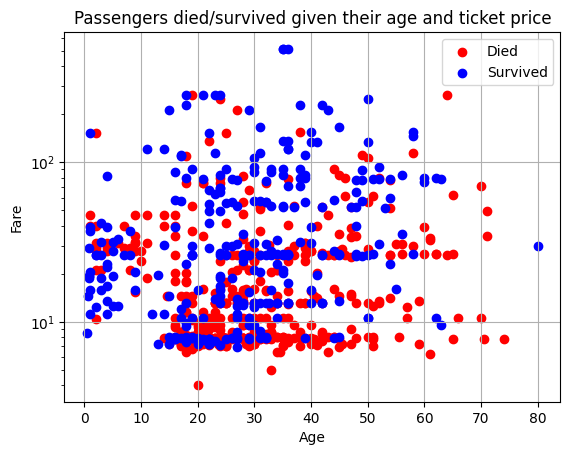

In [ ]:

survived_mask = labels == 1
inputs_survived = inputs[survived_mask, :]
inputs_died = inputs[~survived_mask, :]

#valid_mask = ~np.isnan(inputs[:, age_var_idx])           # matplotlib ignores NaN values, so no need to filter NaNs manually now

plt.scatter(inputs_died[:, AGE_COL_IDX], inputs_died[:, TICKET_PRICE_COL_IDX], c='red', label='Died')
plt.scatter(inputs_survived[:, AGE_COL_IDX], inputs_survived[:, TICKET_PRICE_COL_IDX], c='blue', label='Survived')
plt.legend()
plt.title('Passengers died/survived given their age and ticket price')
plt.grid(True)
plt.xlabel('Age')
plt.ylabel('Fare')
plt.yscale('log')   # logscale on Fare
plt.show()


### Additional plot types

A few visual examples: https://matplotlib.org/stable/plot_types/index.html

**Notable plot types:**
- 1D time series as curves: `plt.plot()` with a sequence of x and a sequence of y coordinate values. The sequence of x values are optional: in case of omission, `arange(seq_len)` is assumed for x.
- `plt.imshow()`, `plt.pcolormesh()` can be used to plot a 2D image or heatmap. A 2D histogram or hypothesis function values can be plotted this way.
- 3D plots: `plt.plot()` or `plt.scatter()` can be used with 3 sequences. `plt.surface()` for surface plotting.